# Ejercicio 3 — Predicción del consumo de energía eléctrica

**Laboratorio de Minería de Datos — metodología CRISP-DM**

Fases: 1) comprensión del negocio · 2) comprensión de los datos · 3) preparación · 4) modelado · 5) evaluación · 6) despliegue (exportación del modelo e interfaz web).

## 1. Comprensión del negocio

Se quiere estimar el **consumo de energía eléctrica** (`Consumo_Energia`, en kWh) a partir de:

| Variable | Significado |
|---|---|
| `Temperatura` | Temperatura en °C |
| `Hora` | Hora del día (1 a 24; la serie se repite cada 24 registros) |
| `Dia_Semana` | Día de la semana (1 = lunes … 7 = domingo) |

**Preguntas a responder:** ¿qué tan bien predice el modelo el consumo?, ¿qué variable tiene **mayor impacto**?, y ¿cuál es su RMSE y su R²?

In [1]:
# Configuración del ejercicio
ARCHIVO = "energia_data.csv"
PREFIJO = "energia"
OBJETIVO = "Consumo_Energia"
VARIABLES = ["Temperatura", "Hora", "Dia_Semana"]
UNIDAD = "kWh"
# Cambio realista de cada variable para leer su coeficiente
PASOS = {
    "Temperatura": (1, "1 °C más de temperatura"),
    "Hora": (1, "1 hora más tarde en el día"),
    "Dia_Semana": (1, "1 día más adelante en la semana"),
}

In [2]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from statsmodels.stats.outliers_influence import variance_inflation_factor

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATOS = RAIZ / "data"
MODELOS = RAIZ / "modelos"
FIGURAS = RAIZ / "figuras"
MODELOS.mkdir(exist_ok=True)
FIGURAS.mkdir(exist_ok=True)

SEMILLA = 42  # misma partición de datos cada vez que se ejecuta
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.float_format", "{:,.4f}".format)

## 2. Comprensión de los datos

In [3]:
df = pd.read_csv(DATOS / ARCHIVO)
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
df.head()

Filas: 10,000 | Columnas: 4


,Temperatura,Hora,Dia_Semana,Consumo_Energia
0,28.8918,1,1,401.9906
1,22.2441,2,2,334.8469
2,20.9090,3,3,326.9261
3,24.9831,4,4,383.0170
4,24.1491,5,5,388.7482


In [4]:
print("Tipos de dato:")
print(df.dtypes.to_string())
print("\nValores nulos por columna:")
print(df.isna().sum().to_string())
print(f"\nFilas duplicadas: {df.duplicated().sum()}")

Tipos de dato:
Temperatura        float64
Hora                 int64
Dia_Semana           int64
Consumo_Energia    float64

Valores nulos por columna:
Temperatura        0
Hora               0
Dia_Semana         0
Consumo_Energia    0

Filas duplicadas: 0


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Temperatura,"10,000.0000",24.9248,5.0040,5.3880,21.5785,24.9005,28.3110,44.6312
Hora,"10,000.0000",12.4936,6.9213,1.0000,6.0000,12.0000,18.0000,24.0000
Dia_Semana,"10,000.0000",3.9994,2.0000,1.0000,2.0000,4.0000,6.0000,7.0000
Consumo_Energia,"10,000.0000",400.0435,63.8252,185.1964,356.7353,399.2704,443.1341,631.0932


### Correlación entre variables

El coeficiente de correlación de Pearson (r) va de −1 a 1 y mide qué tan lineal es la relación entre dos variables.

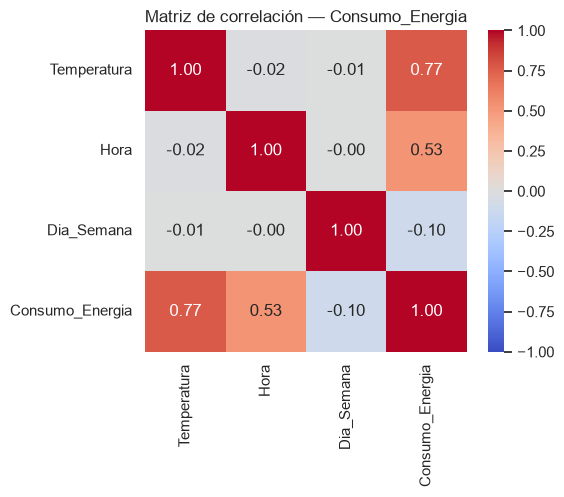

,r con Consumo_Energia
Temperatura,0.7719
Hora,0.5290
Dia_Semana,-0.1022


In [6]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title(f"Matriz de correlación — {OBJETIVO}")
fig.tight_layout(); fig.savefig(FIGURAS / f"{PREFIJO}_correlacion.png", dpi=150); plt.show()

corr[OBJETIVO].drop(OBJETIVO).sort_values(key=abs, ascending=False).rename(f"r con {OBJETIVO}").to_frame()

## 3. Preparación de los datos

Se revisan valores atípicos con la regla del rango intercuartílico (IQR): un valor es atípico si está por debajo de Q1 − 1,5·IQR o por encima de Q3 + 1,5·IQR.

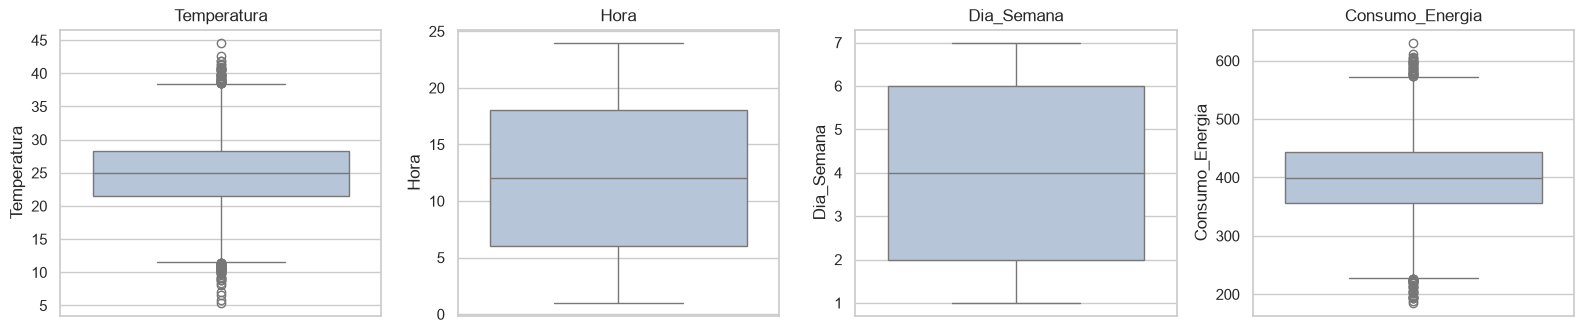

,atípicos (IQR),mínimo,máximo
Temperatura,90,5.3880,44.6312
Hora,0,1.0000,24.0000
Dia_Semana,0,1.0000,7.0000
Consumo_Energia,66,185.1964,631.0932


In [7]:
def contar_atipicos_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).sum())


atipicos = pd.DataFrame({
    "atípicos (IQR)": {c: contar_atipicos_iqr(df[c]) for c in df.columns},
    "mínimo": df.min(),
    "máximo": df.max(),
})

fig, ejes = plt.subplots(1, len(df.columns), figsize=(4 * len(df.columns), 3.5))
for ax, columna in zip(ejes, df.columns):
    sns.boxplot(y=df[columna], ax=ax, color="lightsteelblue")
    ax.set_title(columna)
fig.tight_layout(); fig.savefig(FIGURAS / f"{PREFIJO}_cajas.png", dpi=150); plt.show()
atipicos

**Decisión de limpieza:** no hay nulos ni duplicados. La regla IQR marca 90 temperaturas (por fuera de 11,5–38,4 °C) y 66 consumos (por fuera de 227–573 kWh). Son días muy fríos o muy calurosos con consumos coherentes con esa temperatura, no errores de captura. `Hora` (1–24) y `Dia_Semana` (1–7) están completas y dentro de su rango. **Se conservan las 10.000 filas**.

### 3.1 ¿Cómo tratar la hora y el día de la semana?

La hora es una variable que se repite (después de la 24 vuelve la 1). A veces conviene codificarla con **seno y coseno** para que el modelo entienda que la 24 y la 1 están "cerca". Antes de decidir, se mira cómo cambia el consumo promedio en cada hora y en cada día de la semana.

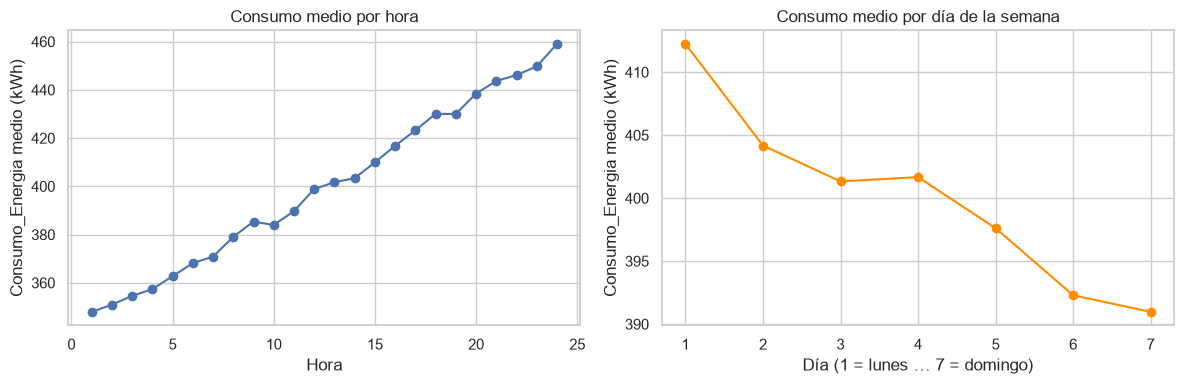

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
df.groupby("Hora")[OBJETIVO].mean().plot(marker="o", ax=ejes[0])
ejes[0].set(title="Consumo medio por hora", xlabel="Hora", ylabel=f"{OBJETIVO} medio ({UNIDAD})")
df.groupby("Dia_Semana")[OBJETIVO].mean().plot(marker="o", ax=ejes[1], color="darkorange")
ejes[1].set(title="Consumo medio por día de la semana", xlabel="Día (1 = lunes … 7 = domingo)", ylabel=f"{OBJETIVO} medio ({UNIDAD})")
fig.tight_layout(); fig.savefig(FIGURAS / f"{PREFIJO}_promedios.png", dpi=150); plt.show()

In [9]:
# Se comparan dos formas de usar la hora con validación cruzada de 5 pliegues
hora_rad = 2 * np.pi * df["Hora"] / 24
alternativas = {
    "Hora lineal (1 a 24)": df[VARIABLES],
    "Hora cíclica (seno y coseno)": df[["Temperatura", "Dia_Semana"]].assign(
        Hora_sen=np.sin(hora_rad), Hora_cos=np.cos(hora_rad)
    ),
}
kfold_hora = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
pd.Series(
    {nombre: cross_val_score(LinearRegression(), Xa, df[OBJETIVO], cv=kfold_hora, scoring="r2").mean()
     for nombre, Xa in alternativas.items()},
    name="R² medio (validación cruzada)",
).to_frame()

,R² medio (validación cruzada)
Hora lineal (1 a 24),0.9004
Hora cíclica (seno y coseno),0.7854


**Decisión:** el consumo medio **sube casi en línea recta** de la hora 1 (≈348 kWh) a la hora 24 (≈459 kWh) y no vuelve a bajar. Por eso la codificación cíclica (que supone que la hora 24 se parece a la 1) empeora el modelo: el R² baja de 0,90 a 0,79. Se usa la **hora tal como viene (1 a 24)**. El día de la semana también muestra una tendencia casi lineal (el consumo baja de lunes a domingo), así que se deja como variable numérica.

### Partición entrenamiento / prueba

El 80 % de las filas se usa para entrenar y el 20 % se guarda para evaluar con datos que el modelo no ha visto.

In [10]:
X = df[VARIABLES]
y = df[OBJETIVO]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)
print(f"Entrenamiento: {len(X_train):,} filas | Prueba: {len(X_test):,} filas")

Entrenamiento: 8,000 filas | Prueba: 2,000 filas


## 4. Modelado — regresión lineal múltiple

El modelo tiene la forma  ŷ = β₀ + β₁·x₁ + β₂·x₂ + β₃·x₃  y se ajusta por mínimos cuadrados ordinarios con `scikit-learn`.

In [11]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

terminos = " ".join(f"{'+' if c >= 0 else '-'} {abs(c):,.4f}·{v}" for v, c in zip(VARIABLES, modelo.coef_))
print("Ecuación del modelo:")
print(f"{OBJETIVO} = {modelo.intercept_:,.4f} {terminos}")

Ecuación del modelo:
Consumo_Energia = 101.2882 + 9.9529·Temperatura + 5.0198·Hora - 3.0312·Dia_Semana


Se ajusta el mismo modelo con `statsmodels` para obtener los **p-valores** (si un coeficiente es estadísticamente distinto de cero) y el **VIF** (multicolinealidad: un VIF mayor que 5 indica que las variables se solapan entre sí).

In [12]:
X_train_const = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_train_const).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:        Consumo_Energia   R-squared:                       0.901
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                 2.438e+04
Date:                Mon, 23 Nov 2026   Prob (F-statistic):               0.00
Time:                        14:29:38   Log-Likelihood:                -35309.
No. Observations:                8000   AIC:                         7.063e+04
Df Residuals:                    7996   BIC:                         7.065e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const         101.2882      1.298     78.037      

In [13]:
vif = pd.Series(
    [variance_inflation_factor(X_train_const.values, i) for i in range(1, X_train_const.shape[1])],
    index=VARIABLES,
    name="VIF",
)
vif.to_frame()

,VIF
Temperatura,1.0004
Hora,1.0004
Dia_Semana,1.0001


## 5. Evaluación del modelo

In [14]:
def metricas(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y_real, y_pred), "R2": r2_score(y_real, y_pred)}


pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)
m_train = metricas(y_train, pred_train)
m_test = metricas(y_test, pred_test)

kfold = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
r2_cv = cross_val_score(LinearRegression(), X, y, cv=kfold, scoring="r2")

pd.DataFrame({"Entrenamiento": m_train, "Prueba": m_test}).rename(index={"R2": "R²"})

,Entrenamiento,Prueba
MSE,399.1937,429.5187
RMSE,19.9798,20.7248
MAE,15.9174,16.5101
R²,0.9015,0.8968


In [15]:
print(f"R² con validación cruzada (5 pliegues): {r2_cv.mean():.4f} ± {r2_cv.std():.4f}\n")
print(f"• El modelo explica el {m_test['R2']:.1%} de la variación de {OBJETIVO} en datos que no vio al entrenar.")
print(f"• MSE = {m_test['MSE']:,.2f} ({UNIDAD})²: promedio de los errores al cuadrado.")
print(f"• RMSE = {m_test['RMSE']:,.2f} {UNIDAD}: error típico en las unidades originales "
      f"({m_test['RMSE'] / y.mean():.1%} del promedio de {OBJETIVO}, que es {y.mean():,.2f} {UNIDAD}).")
print(f"• MAE = {m_test['MAE']:,.2f} {UNIDAD}: en promedio la predicción se aleja eso del valor real.")
diferencia = m_train["R2"] - m_test["R2"]
print(f"• R² entrenamiento − R² prueba = {diferencia:+.4f} → "
      + ("no hay señales de sobreajuste." if abs(diferencia) < 0.05 else "revisar posible sobreajuste."))

R² con validación cruzada (5 pliegues): 0.9004 ± 0.0035

• El modelo explica el 89.7% de la variación de Consumo_Energia en datos que no vio al entrenar.
• MSE = 429.52 (kWh)²: promedio de los errores al cuadrado.
• RMSE = 20.72 kWh: error típico en las unidades originales (5.2% del promedio de Consumo_Energia, que es 400.04 kWh).
• MAE = 16.51 kWh: en promedio la predicción se aleja eso del valor real.
• R² entrenamiento − R² prueba = +0.0046 → no hay señales de sobreajuste.


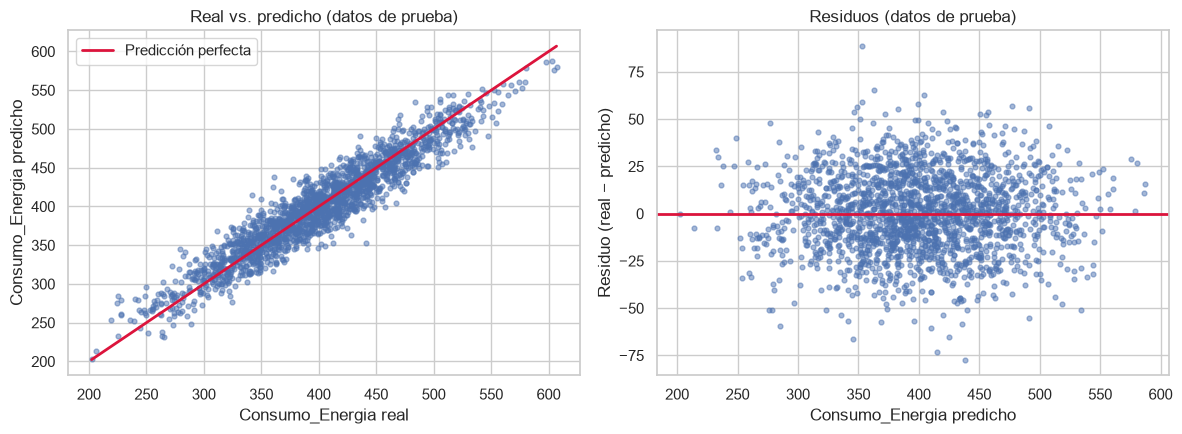

In [16]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
ejes[0].scatter(y_test, pred_test, alpha=0.5, s=12)
limites = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
ejes[0].plot(limites, limites, color="crimson", lw=2, label="Predicción perfecta")
ejes[0].set(xlabel=f"{OBJETIVO} real", ylabel=f"{OBJETIVO} predicho", title="Real vs. predicho (datos de prueba)")
ejes[0].legend()

residuos = y_test - pred_test
ejes[1].scatter(pred_test, residuos, alpha=0.5, s=12)
ejes[1].axhline(0, color="crimson", lw=2)
ejes[1].set(xlabel=f"{OBJETIVO} predicho", ylabel="Residuo (real − predicho)", title="Residuos (datos de prueba)")
fig.tight_layout(); fig.savefig(FIGURAS / f"{PREFIJO}_evaluacion.png", dpi=150); plt.show()

### Interpretación de los coeficientes e importancia de cada variable

- **Coeficiente:** cuánto cambia la predicción cuando la variable sube una unidad y las demás se mantienen fijas.
- **Coeficiente estandarizado (β):** el mismo efecto medido en desviaciones estándar; como no depende de las unidades, permite **comparar qué variable pesa más**.
- **Efecto en el rango típico:** cuánto cambia la predicción al pasar la variable de su percentil 25 a su percentil 75 (el 50 % central de los datos).

In [17]:
desv_y = y_train.std()
coeficientes = pd.DataFrame({
    "coeficiente": modelo.coef_,
    "coef_estandarizado": [c * X_train[v].std() / desv_y for v, c in zip(VARIABLES, modelo.coef_)],
    "efecto_rango_típico": [c * (X[v].quantile(0.75) - X[v].quantile(0.25)) for v, c in zip(VARIABLES, modelo.coef_)],
    "p_valor": ols.pvalues[VARIABLES].values,
}, index=VARIABLES)
coeficientes["importancia_%"] = 100 * coeficientes["coef_estandarizado"].abs() / coeficientes["coef_estandarizado"].abs().sum()
coeficientes = coeficientes.sort_values("importancia_%", ascending=False)
coeficientes

,coeficiente,coef_estandarizado,efecto_rango_típico,p_valor,importancia_%
Temperatura,9.9529,0.7803,67.0069,0.0000,54.8677
Hora,5.0198,0.5464,60.2378,0.0000,38.4218
Dia_Semana,-3.0312,-0.0954,-12.1247,0.0000,6.7105


In [18]:
print(f"Intercepto (β₀) = {modelo.intercept_:,.4f} {UNIDAD}: valor teórico de {OBJETIVO} si todas las variables valieran 0.\n")
for variable, fila in coeficientes.iterrows():
    paso, texto = PASOS[variable]
    efecto = fila["coeficiente"] * paso
    direccion = "sube" if efecto >= 0 else "baja"
    significancia = "significativo" if fila["p_valor"] < 0.05 else "NO significativo"
    print(f"• {variable}: con {texto}, {OBJETIVO} {direccion} {abs(efecto):,.4f} {UNIDAD}, "
          f"manteniendo fijas las demás variables.")
    print(f"  p-valor = {fila['p_valor']:.3g} ({significancia} al 5 %) | importancia relativa = {fila['importancia_%']:.1f} %\n")
print(f"Variable con MAYOR impacto: {coeficientes.index[0]} "
      f"(β estandarizado = {coeficientes['coef_estandarizado'].iloc[0]:+.3f}).")

Intercepto (β₀) = 101.2882 kWh: valor teórico de Consumo_Energia si todas las variables valieran 0.

• Temperatura: con 1 °C más de temperatura, Consumo_Energia sube 9.9529 kWh, manteniendo fijas las demás variables.
  p-valor = 0 (significativo al 5 %) | importancia relativa = 54.9 %

• Hora: con 1 hora más tarde en el día, Consumo_Energia sube 5.0198 kWh, manteniendo fijas las demás variables.
  p-valor = 0 (significativo al 5 %) | importancia relativa = 38.4 %

• Dia_Semana: con 1 día más adelante en la semana, Consumo_Energia baja 3.0312 kWh, manteniendo fijas las demás variables.
  p-valor = 1.04e-155 (significativo al 5 %) | importancia relativa = 6.7 %

Variable con MAYOR impacto: Temperatura (β estandarizado = +0.780).


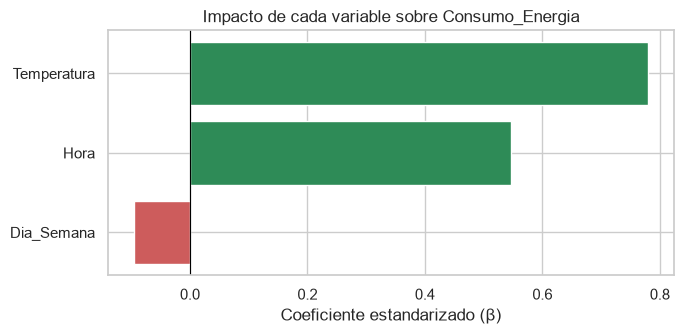

In [19]:
fig, ax = plt.subplots(figsize=(7, 3.5))
orden = coeficientes.iloc[::-1]
colores = ["seagreen" if c >= 0 else "indianred" for c in orden["coef_estandarizado"]]
ax.barh(orden.index, orden["coef_estandarizado"], color=colores)
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Coeficiente estandarizado (β)", title=f"Impacto de cada variable sobre {OBJETIVO}")
fig.tight_layout(); fig.savefig(FIGURAS / f"{PREFIJO}_importancia.png", dpi=150); plt.show()

## 6. Relación de cada variable independiente con la variable dependiente

Cada punto es una observación. La línea roja es la recta de regresión simple de esa variable sola contra la variable dependiente.

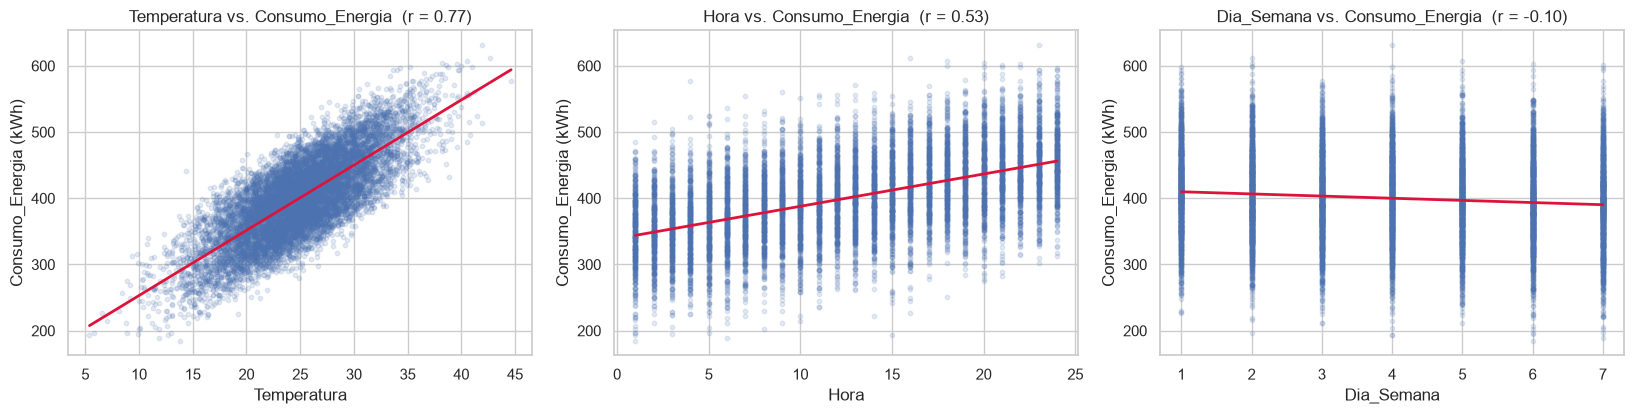

In [20]:
fig, ejes = plt.subplots(1, len(VARIABLES), figsize=(5.5 * len(VARIABLES), 4.3))
transparencia = 0.15 if len(df) > 5000 else 0.4
for ax, variable in zip(ejes, VARIABLES):
    ax.scatter(df[variable], df[OBJETIVO], alpha=transparencia, s=10)
    pendiente, corte = np.polyfit(df[variable], df[OBJETIVO], 1)
    xs = np.linspace(df[variable].min(), df[variable].max(), 100)
    ax.plot(xs, corte + pendiente * xs, color="crimson", lw=2)
    r = df[variable].corr(df[OBJETIVO])
    ax.set(xlabel=variable, ylabel=f"{OBJETIVO} ({UNIDAD})", title=f"{variable} vs. {OBJETIVO}  (r = {r:.2f})")
fig.tight_layout(); fig.savefig(FIGURAS / f"{PREFIJO}_dispersion.png", dpi=150); plt.show()

## 7. Exportación del modelo

En Python hay dos formas habituales de guardar un modelo entrenado:

| | `pickle` | `joblib` |
|---|---|---|
| Qué es | Módulo estándar de Python | Librería que usa scikit-learn |
| Guardar | `pickle.dump(obj, open("m.pkl", "wb"))` | `joblib.dump(obj, "m.joblib")` |
| Cargar | `pickle.load(open("m.pkl", "rb"))` | `joblib.load("m.joblib")` |
| Ventaja | No requiere instalar nada | Más eficiente con arreglos grandes de NumPy |

Se usa **joblib**, que es lo que recomienda la documentación de scikit-learn. Junto al modelo se guardan las variables, las métricas, los coeficientes y los rangos de los datos, para que la interfaz web pueda mostrarlos. Solo se guardan objetos de scikit-learn y tipos básicos de Python, así que la app no necesita el código de este notebook para cargarlo. Al cargarlo se debe usar la **misma versión de scikit-learn** (queda registrada en el archivo).

In [21]:
artefacto = {
    "modelo": modelo,
    "variables": VARIABLES,
    "objetivo": OBJETIVO,
    "unidad": UNIDAD,
    "intercepto": float(modelo.intercept_),
    "coeficientes": {v: float(c) for v, c in zip(VARIABLES, modelo.coef_)},
    "coef_estandarizados": coeficientes["coef_estandarizado"].astype(float).to_dict(),
    "p_valores": coeficientes["p_valor"].astype(float).to_dict(),
    "metricas_prueba": {k: float(v) for k, v in m_test.items()},
    "metricas_entrenamiento": {k: float(v) for k, v in m_train.items()},
    "r2_validacion_cruzada": {"media": float(r2_cv.mean()), "desviacion": float(r2_cv.std())},
    "rangos": {
        v: {"min": float(df[v].min()), "max": float(df[v].max()), "mediana": float(df[v].median())}
        for v in VARIABLES
    },
    "filas": {"entrenamiento": len(X_train), "prueba": len(X_test)},
    "version_sklearn": sklearn.__version__,
}

ruta_modelo = MODELOS / f"modelo_{PREFIJO}.joblib"
joblib.dump(artefacto, ruta_modelo)
print(f"Modelo guardado en {ruta_modelo.relative_to(RAIZ)} ({ruta_modelo.stat().st_size / 1024:.1f} KB)")

Modelo guardado en modelos\modelo_energia.joblib (1.6 KB)


Se carga el archivo de nuevo y se comprueba que predice exactamente lo mismo que el modelo original:

In [22]:
cargado = joblib.load(ruta_modelo)
ejemplo = X_test.head(5)
comparacion = ejemplo.copy()
comparacion[f"{OBJETIVO} real"] = y_test.head(5).values
comparacion["predicción (modelo original)"] = modelo.predict(ejemplo)
comparacion["predicción (modelo cargado)"] = cargado["modelo"].predict(ejemplo)
assert np.allclose(comparacion["predicción (modelo original)"], comparacion["predicción (modelo cargado)"])
comparacion

,Temperatura,Hora,Dia_Semana,Consumo_Energia real,predicción (modelo original),predicción (modelo cargado)
6252,29.0501,13,2,487.3160,449.6156,449.6156
4684,24.6945,5,2,373.2681,366.1061,366.1061
1731,14.8710,4,3,263.0977,260.2826,260.2826
4742,31.6628,15,4,476.8562,479.5959,479.5959
4521,26.9961,10,7,448.4677,398.9571,398.9571


## 8. Conclusiones

1. **Desempeño:** el modelo explica el **89,7 %** de la variación del consumo en los datos de prueba (R² = 0,8968), con un **RMSE de 20,72 kWh** (5,2 % del consumo promedio, 400,04 kWh) y un MAE de 16,51 kWh. El R² de entrenamiento (0,9015) y el de validación cruzada (0,9004 ± 0,0035) son casi iguales: no hay sobreajuste.
2. **Interpretación de los coeficientes** (las tres variables son significativas, p < 0,05):
   - `Temperatura`: cada °C adicional **sube** el consumo 9,95 kWh (por ejemplo, por el aire acondicionado).
   - `Hora`: cada hora más tarde en el día **sube** el consumo 5,02 kWh.
   - `Dia_Semana`: cada día más adelante en la semana **baja** el consumo 3,03 kWh, así que el domingo consume unos 18 kWh menos que el lunes.
3. **Variable de mayor impacto: la Temperatura** (β = 0,780; 54,9 % de la importancia), seguida de la Hora (β = 0,546; 38,4 %). El día de la semana tiene un efecto pequeño (6,7 %).
4. **Codificación de la hora:** se comprobó con validación cruzada que usar la hora lineal (R² = 0,900) funciona mejor que la codificación con seno y coseno (R² = 0,785), porque en estos datos el consumo crece a lo largo del día en vez de seguir un ciclo.
5. **Limitación:** fuera del rango de temperaturas observado (5,4 °C a 44,6 °C) el modelo extrapola, y sus predicciones son menos confiables.